## Machine Learning: Predicting Healthcare Insurance Charges



## Objective

The objective of this notebook is to develop and evaluate machine learning regression models to predict healthcare insurance charges, identify the best-performing model, and examine the key factors influencing its predictions.

## Inputs

This notebook uses the `insurance.csv` dataset, with `charges` as the target variable and the remaining selected demographic and lifestyle variables as input features.

## Outputs

This notebook produces a trained machine-learning model, model evaluation results, diagnostic visualisations, feature-importance analysis and predicted healthcare insurance charges.

## 1. Initialising the Project

This notebook is stored in the `notebooks` directory. The working directory is changed to the main project directory so that project files can be accessed using relative paths.

In [15]:
import os

# Set the working directory to the main project folder
project_dir = r"D:\Code\Assessment 2\code-institute_Assessment_2_Healthcare_Insurance_ML\code-institute-_-Assessment-2-Healthcare-Insurance-ML"

# Change the working directory
os.chdir(project_dir)

# Check the new working directory
print(os.getcwd())

D:\Code\Assessment 2\code-institute_Assessment_2_Healthcare_Insurance_ML\code-institute-_-Assessment-2-Healthcare-Insurance-ML


## Import Libraries

In [16]:
# Data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Visualisation settings
sns.set_theme(style="whitegrid")



## Loading the Cleaned Dataset

The cleaned dataset produced during the ETL and exploratory data analysis stage is loaded for statistical analysis.

The original raw dataset is not modified. The statistical analysis uses the cleaned dataset stored in the project's `data` directory.

In [17]:
# Load the cleaned dataset
data_path = "output/cleaned_insurance.csv"
DATA_Cleaned = pd.read_csv(data_path)

print("Dataset loaded successfully.")
print(f"Rows: {DATA_Cleaned.shape[0]}")
print(f"Columns: {DATA_Cleaned.shape[1]}")

display(DATA_Cleaned.head())

Dataset loaded successfully.
Rows: 1337
Columns: 8


,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,Overweight
1,18,male,33.770,1,no,southeast,1725.55230,Obese
2,28,male,33.000,3,no,southeast,4449.46200,Obese
3,33,male,22.705,0,no,northwest,21984.47061,Normal
4,32,male,28.880,0,no,northwest,3866.85520,Overweight


## 2. Data Validation and Initial Inspection

Before developing machine-learning models, the cleaned dataset must be checked to ensure that it is suitable for analysis.

This step examines:

- **Dataset structure:** the number of rows and columns.
- **Data types:** whether numerical and categorical variables have appropriate types.
- **Missing values:** whether any values are absent.
- **Duplicate records:** whether identical rows remain in the dataset.
- **Target variable:** whether `charges` exists and contains valid numerical values.
- **Descriptive statistics:** the distribution and range of the numerical variables.

These checks help identify potential data-quality problems before model development. The cleaned dataset will be retained as the source for the subsequent modelling steps.

In [18]:
# ============================================================
# 2. DATA VALIDATION AND INITIAL INSPECTION
# ============================================================

# 1. Inspect the dataset dimensions
print("Dataset dimensions")
print(f"Number of rows: {DATA_Cleaned.shape[0]}")
print(f"Number of columns: {DATA_Cleaned.shape[1]}")

# 2. Display column names
print("\nColumn names:")
print(DATA_Cleaned.columns.tolist())

# 3. Inspect data types and non-null counts
print("\nDataset information:")
DATA_Cleaned.info()

# 4. Check missing values
print("\nMissing values by column:")
display(
    DATA_Cleaned.isnull()
    .sum()
    .rename("Missing values")
    .to_frame()
)

# 5. Check duplicate rows
duplicate_count = DATA_Cleaned.duplicated().sum()

print(f"\nNumber of duplicate rows: {duplicate_count}")

# 6. Check whether the target variable exists
if "charges" in DATA_Cleaned.columns:
    print("\nTarget variable: charges")
    print(f"Data type: {DATA_Cleaned['charges'].dtype}")
    print(f"Missing target values: {DATA_Cleaned['charges'].isnull().sum()}")
    print(f"Non-positive charges: {(DATA_Cleaned['charges'] <= 0).sum()}")

    print("\nDescriptive statistics for charges:")
    display(DATA_Cleaned["charges"].describe().to_frame())

else:
    raise ValueError(
        "The target variable 'charges' was not found in the dataset."
    )

# 7. Display a sample of the data
print("\nFirst five rows:")
display(DATA_Cleaned.head())

Dataset dimensions
Number of rows: 1337
Number of columns: 8

Column names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges', 'bmi_category']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1337 entries, 0 to 1336
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   age           1337 non-null   int64  
 1   sex           1337 non-null   object 
 2   bmi           1337 non-null   float64
 3   children      1337 non-null   int64  
 4   smoker        1337 non-null   object 
 5   region        1337 non-null   object 
 6   charges       1337 non-null   float64
 7   bmi_category  1337 non-null   object 
dtypes: float64(2), int64(2), object(4)
memory usage: 83.7+ KB

Missing values by column:


,Missing values
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0
bmi_category,0



Number of duplicate rows: 0

Target variable: charges
Data type: float64
Missing target values: 0
Non-positive charges: 0

Descriptive statistics for charges:


,charges
count,1337.000000
mean,13279.121487
std,12110.359656
min,1121.873900
25%,4746.344000
50%,9386.161300
75%,16657.717450
max,63770.428010



First five rows:


,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,Overweight
1,18,male,33.770,1,no,southeast,1725.55230,Obese
2,28,male,33.000,3,no,southeast,4449.46200,Obese
3,33,male,22.705,0,no,northwest,21984.47061,Normal
4,32,male,28.880,0,no,northwest,3866.85520,Overweight


## 3. Feature Selection and Target Definition

The objective of this project is to predict healthcare insurance charges using customer characteristics.

The dataset is divided into two components:

- **Feature matrix (`X`):** contains the independent variables used by the models.
- **Target variable (`y`):** contains the actual insurance charges that the models will learn to predict.

The target variable is excluded from the feature matrix to prevent the model from using the answer as an input.

Numerical and categorical features are identified separately because they may require different preprocessing methods. Preprocessing and model training will subsequently be organised into pipelines to support reproducibility and reduce the risk of data leakage.

In [19]:
# ============================================================
# 3. FEATURE SELECTION AND TARGET DEFINITION
# ============================================================

# Define the target variable
target = "charges"



# Separate features (X) and target (y)
X = DATA_Cleaned.drop(columns=[target]).copy()
y = DATA_Cleaned[target].copy()

# Identify numerical and categorical features
numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Display the results
# print("Feature and target preparation completed.")
print(f"\nNumber of observations: {len(X)}")
print(f"Number of input features: {X.shape[1]}")
print(f"Target variable: {target}")

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)




Number of observations: 1337
Number of input features: 7
Target variable: charges

Numerical features:
['age', 'bmi', 'children']

Categorical features:
['sex', 'smoker', 'region', 'bmi_category']


## 4. Train–Test Split

To evaluate the ability of a machine-learning model to predict unseen insurance charges, the dataset is divided into two subsets:

- **Training set (80%):** used to train the models.
- **Testing set (20%):** reserved for evaluating the models on data they have not seen during training.

The split uses `random_state=42` to make the results reproducible. The same split will be used when comparing models, ensuring a fairer comparison.

The data will be split before fitting preprocessing steps. This helps prevent information from the test set from influencing model training.

In [20]:
# ============================================================
# 4. TRAIN–TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Split the features and target
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Report the size of each subset
print("Training and testing split completed.")
print(f"Original dataset: {len(X)} observations")
print(f"Training set:     {len(X_train)} observations")
print(f"Testing set:      {len(X_test)} observations")

print(f"\nTraining proportion: {len(X_train) / len(X):.1%}")
print(f"Testing proportion:  {len(X_test) / len(X):.1%}")

# Check the dimensions
print("\nFeature dimensions:")
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")

# Compare target distributions
print("\nTraining target summary:")
display(y_train.describe().to_frame())

print("\nTesting target summary:")
display(y_test.describe().to_frame())

# Verify that the split contains no overlapping row indices
assert set(X_train.index).isdisjoint(set(X_test.index)), (
    "Training and testing sets contain overlapping observations."
)

print("\nValidation passed: training and testing indices do not overlap.")

Training and testing split completed.
Original dataset: 1337 observations
Training set:     1069 observations
Testing set:      268 observations

Training proportion: 80.0%
Testing proportion:  20.0%

Feature dimensions:
X_train: (1069, 7)
X_test:  (268, 7)

Training target summary:


,charges
count,1069.000000
mean,13030.203369
std,11706.530971
min,1121.873900
25%,4747.052900
50%,9290.139500
75%,16450.894700
max,62592.873090



Testing target summary:


,charges
count,268.000000
mean,14272.007559
std,13581.026802
min,1131.506600
25%,4731.707250
50%,9535.650600
75%,17781.104820
max,63770.428010



Validation passed: training and testing indices do not overlap.


## 5. Baseline Model

A baseline model provides a reference point against which more advanced machine-learning models can be compared.

In this project, a `DummyRegressor` using the mean strategy predicts the average insurance charge observed in the training data for every observation in the test set.

The baseline does not learn relationships between customer characteristics and insurance charges. Its purpose is to establish the minimum performance that a useful predictive model should improve upon.

The baseline and Linear Regression models will be evaluated using the same test observations and the same metrics: MAE, RMSE and R².

In [21]:
# ============================================================
# 6. BASELINE REGRESSION MODEL
# ============================================================

from sklearn.dummy import DummyRegressor
# from sklearn.metrics import (
#     mean_absolute_error,
#     mean_squared_error,
#     r2_score
# )
# import numpy as np
# import pandas as pd

# 1. Create and train the baseline model
baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train)

# 2. Predict charges for the test set
y_pred_baseline = baseline_model.predict(X_test)

# 3. Evaluate the baseline
baseline_results = {
    "Model": "Mean Baseline",
    "MAE": mean_absolute_error(y_test, y_pred_baseline),
    "RMSE": np.sqrt(
        mean_squared_error(y_test, y_pred_baseline)
    ),
    "R²": r2_score(y_test, y_pred_baseline)
}


mae_BLM = mean_absolute_error(y_test, y_pred_baseline)
rmse_BLM = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
r2_BLM = r2_score(y_test, y_pred_baseline)
# print("Linear Regression — Initial Results")
print("-" * 40)
print(f"MAE:  {mae_BLM:,.2f}")
print(f"RMSE: {rmse_BLM:,.2f}")
print(f"R²:   {r2_BLM:.4f}")



----------------------------------------
MAE:  9,861.80
RMSE: 13,612.43
R²:   -0.0084


###  REGRESSION MODEL


In [22]:
# ============================================================
# 5. PREPROCESSING PIPELINE AND FIRST REGRESSION MODEL
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Define preprocessing for numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

# 2. Build a pipeline combining preprocessing and regression
linear_regression_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

# 3. Train the model using only the training data
linear_regression_pipeline.fit(X_train, y_train)

# 4. Predict charges for the unseen test data
y_pred_lr = linear_regression_pipeline.predict(X_test)

linear_results = {
    "Model": "Linear Regression",
    "MAE": mean_absolute_error(y_test, y_pred_lr),
    "RMSE": np.sqrt(
        mean_squared_error(y_test, y_pred_lr)
    ),
    "R²": r2_score(y_test, y_pred_lr)
}

# 5. Evaluate model performance
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression — Initial Results")
print("-" * 40)
print(f"MAE:  {mae_lr:,.2f}")
print(f"RMSE: {rmse_lr:,.2f}")
print(f"R²:   {r2_lr:.4f}")


# 5. Display the comparison
comparison_df = pd.DataFrame(
    [baseline_results, linear_results]
).set_index("Model")

print("Baseline vs Linear Regression")
display(comparison_df.round(4))

Linear Regression — Initial Results
----------------------------------------
MAE:  4,338.92
RMSE: 6,024.00
R²:   0.8025
Baseline vs Linear Regression


,MAE,RMSE,R²
Model,,,
Mean Baseline,9861.7979,13612.4260,-0.0084
Linear Regression,4338.9238,6024.0047,0.8025


### Baseline Model and Performance Comparison

A Mean Baseline model was developed using `DummyRegressor` with the mean strategy to establish a reference point for evaluating the regression models. The baseline achieved an MAE of 9,861.80, an RMSE of 13,612.43, and an R² score of -0.0084.

Linear Regression achieved substantially better results, with an MAE of 4,338.92, an RMSE of 6,024.00, and an R² score of 0.8025. Compared with the baseline, Linear Regression reduced MAE by approximately 56% and RMSE by approximately 55.7%. These results indicate that Linear Regression provides considerably better predictive performance than simply predicting the mean insurance charge. Therefore, the baseline provides a useful benchmark for evaluating the more informative regression models developed in this project.

## 7. Regression Model Comparison

Different regression algorithms can capture different types of relationships between customer characteristics and insurance charges.

This section compares several models:

- **Linear Regression:** provides a simple linear reference model.
- **Ridge Regression:** applies regularisation to reduce the influence of large regression coefficients.
- **Random Forest:** combines multiple decision trees to model nonlinear relationships.
- **Extra Trees:** introduces additional randomisation into tree construction.
- **Gradient Boosting:** builds an ensemble of trees sequentially, with each stage attempting to improve the previous model's predictions.

All models will use the same training and testing observations and the same preprocessing pipeline. Performance will be evaluated using MAE, RMSE and R².

The test set will remain separate from model fitting so that it can provide an independent final evaluation.

In [23]:
# ============================================================
# 7. COMPARE REGRESSION MODELS
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.base import clone


# Define candidate models
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

# Store model results and fitted pipelines
model_results = []
fitted_models = {}

for name, estimator in models.items():

    # Create an independent preprocessing pipeline for each model
    pipeline = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("model", estimator)
        ]
    )

    # Fit using training data only
    pipeline.fit(X_train, y_train)

    # Predict on the same held-out test set
    predictions = pipeline.predict(X_test)

    # Calculate evaluation metrics
    model_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R²": r2_score(y_test, predictions)
    })

    fitted_models[name] = pipeline

# Display models ordered by MAE
model_comparison = (
    pd.DataFrame(model_results)
    .sort_values("MAE")
    .set_index("Model")
)

print("Regression Model Comparison — Test Set")
display(model_comparison.round(4))

Regression Model Comparison — Test Set


,MAE,RMSE,R²
Model,,,
Random Forest,2563.3500,4614.0028,0.8841
Gradient Boosting,2603.0424,4370.8187,0.8960
Extra Trees,2690.0835,5134.7945,0.8565
Ridge Regression,4337.7070,6026.4767,0.8024
Linear Regression,4338.9238,6024.0047,0.8025


### Comparison of Regression Models

The performance of Random Forest, Gradient Boosting, Extra Trees and Ridge Regression was compared with the Linear Regression benchmark using MAE, RMSE and R². The ensemble models demonstrated substantially better predictive performance than the linear models. Random Forest achieved the lowest MAE of 2,563.35, while Gradient Boosting achieved the lowest RMSE of 4,370.82 and the highest R² of 0.8960. Compared with Linear Regression, Gradient Boosting reduced MAE by approximately 40.0% and RMSE by approximately 27.5%. Its R² score indicates that the model explains approximately 89.6% of the variation in insurance charges in the test dataset. These findings suggest that the ensemble methods capture patterns in the data that the linear models do not capture as effectively. However, final model selection should also consider validation performance, model complexity and interpretability.

## 8. Cross-Validation for Model Selection

A single train–test split can produce results that depend partly on which observations are assigned to each subset. Cross-validation helps assess whether a model performs consistently across different subsets of the available training data.

In this section, five-fold cross-validation is applied to the training set. The training data are divided into five folds; each fold is used once for validation while the remaining four folds are used for fitting.

The models are compared using MAE, RMSE and R². The held-out test set is not used during cross-validation and remains reserved for the final evaluation of the selected model.

Cross-validation results will help determine whether Gradient Boosting or Random Forest is the more reliable choice.

In [24]:
# ============================================================
# 8. FIVE-FOLD CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import KFold, cross_validate


# Define reproducible five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define the evaluation metrics
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cv_results = []

for name, estimator in models.items():

    # Build a fresh pipeline for each model
    pipeline = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("model", clone(estimator))
        ]
    )

    # Cross-validation uses only the training data
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False
    )

    # Convert negative error scores to positive values
    cv_results.append({
        "Model": name,
        "Mean MAE": -scores["test_MAE"].mean(),
        "MAE SD": scores["test_MAE"].std(),
        "Mean RMSE": -scores["test_RMSE"].mean(),
        "RMSE SD": scores["test_RMSE"].std(),
        "Mean R²": scores["test_R2"].mean(),
        "R² SD": scores["test_R2"].std()
    })

# Display models ordered by mean MAE
cv_comparison = (
    pd.DataFrame(cv_results)
    .sort_values("Mean MAE")
    .set_index("Model")
)

print("Five-Fold Cross-Validation Results — Training Set")
display(cv_comparison.round(4))

Five-Fold Cross-Validation Results — Training Set


,Mean MAE,MAE SD,Mean RMSE,RMSE SD,Mean R²,R² SD
Model,,,,,,
Gradient Boosting,2679.8181,45.0700,4592.1618,149.6780,0.8433,0.0213
Extra Trees,2682.2645,173.1765,5065.7403,231.3277,0.8085,0.0332
Random Forest,2727.7877,129.8256,4860.9750,224.4457,0.8235,0.0312
Ridge Regression,4256.5951,161.9809,6047.3237,151.7662,0.7298,0.0250
Linear Regression,4258.7403,159.7542,6048.2576,150.2103,0.7297,0.0253


### Cross-Validation for Model Selection

Five-fold cross-validation was used to compare the regression models and assess the consistency of their predictive performance. Gradient Boosting achieved the lowest mean MAE (2,679.82), the lowest mean RMSE (4,592.16), and the highest mean R² (0.8433). Its MAE standard deviation of 45.07 also indicated consistent performance across the five folds. Although Extra Trees achieved a similar mean MAE, its mean RMSE was higher and its mean R² was lower. Random Forest also performed well but did not outperform Gradient Boosting across the three mean evaluation metrics. Based on these cross-validation results, Gradient Boosting was selected as the leading candidate for further evaluation against the held-out test set.

## 9. Final Test-Set Evaluation

Based on the five-fold cross-validation results, Gradient Boosting was selected as the leading candidate model.

The selected model was evaluated on the held-out test set using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²). The model achieved an MAE of **2,603.04**, an RMSE of **4,370.82**, and an R² of **0.8960**.

Actual and predicted insurance charges were compared visually, and prediction residuals were examined to identify potential systematic errors. The test set was not used to fit the model or perform cross-validation, providing an independent evaluation of the selected model under the current experimental setup.

The model's performance was interpreted using all three evaluation metrics alongside its limitations, rather than relying on a single measure of predictive accuracy.

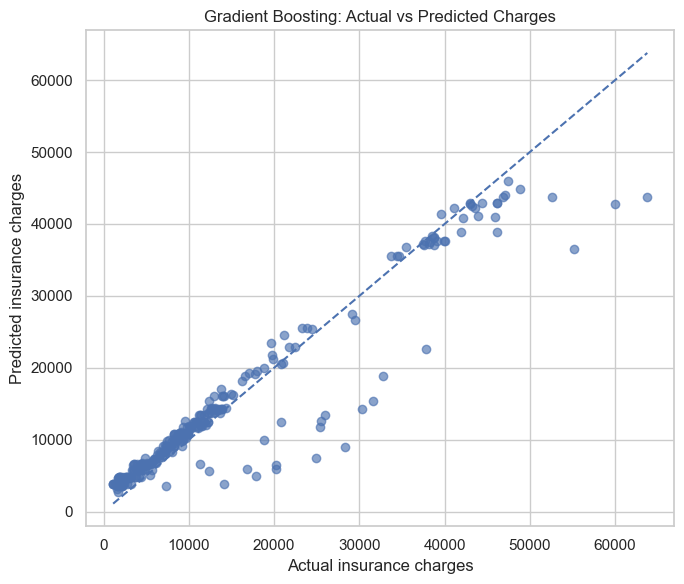

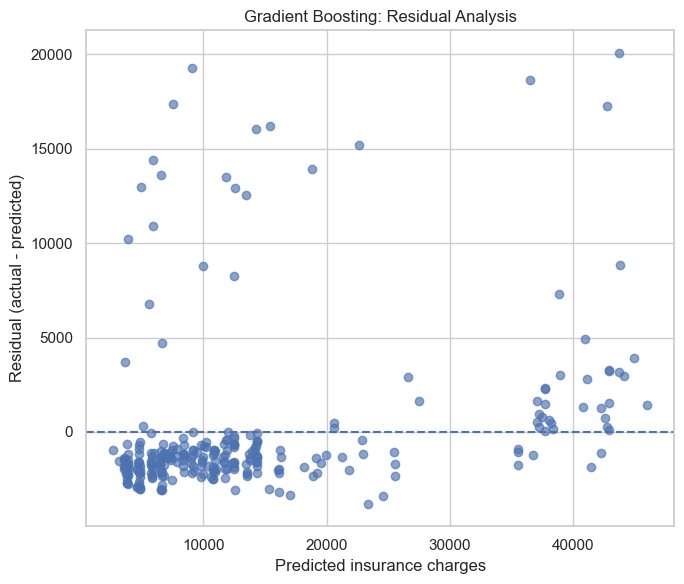

In [25]:
# ============================================================
# 9. FINAL TEST-SET EVALUATION — GRADIENT BOOSTING
# ============================================================


# Retrieve the Gradient Boosting pipeline
best_model = fitted_models["Gradient Boosting"]

# Generate predictions for the unseen test observations
y_pred_gb = best_model.predict(X_test)

# Calculate residuals: actual minus predicted
residuals = y_test.to_numpy() - y_pred_gb

# Calculate evaluation metrics
final_metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Test-set result": [
        mean_absolute_error(y_test, y_pred_gb),
        np.sqrt(mean_squared_error(y_test, y_pred_gb)),
        r2_score(y_test, y_pred_gb)
    ]
})



# Compare actual and predicted charges
prediction_comparison = pd.DataFrame({
    "Actual charges": y_test.to_numpy(),
    "Predicted charges": y_pred_gb,
    "Residual": residuals
})



# Plot 1: Actual vs predicted charges
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_gb, alpha=0.65)

# Reference line for perfect predictions
axis_min = min(y_test.min(), y_pred_gb.min())
axis_max = max(y_test.max(), y_pred_gb.max())

plt.plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    linestyle="--"
)

plt.xlabel("Actual insurance charges")
plt.ylabel("Predicted insurance charges")
plt.title("Gradient Boosting: Actual vs Predicted Charges")
plt.tight_layout()
plt.show()

# Plot 2: Residuals vs predicted charges
plt.figure(figsize=(7, 6))
plt.scatter(y_pred_gb, residuals, alpha=0.65)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted insurance charges")
plt.ylabel("Residual (actual - predicted)")
plt.title("Gradient Boosting: Residual Analysis")
plt.tight_layout()
plt.show()

### Visual Evaluation and Residual Analysis

The actual-versus-predicted plot indicates that Gradient Boosting provides reasonably accurate predictions for many observations, particularly those with lower insurance charges. However, several observations deviate substantially from the line of perfect agreement. The model appears to underestimate some cases with high actual charges, indicating a limitation in predicting the most expensive insurance claims.

The residual plot supports this observation. Residuals are not distributed evenly around zero, and several large positive residuals indicate substantial underprediction. This pattern suggests that the model may not capture all the factors associated with unusually high insurance charges. Although the model achieved an R² of 0.8960, the visual analysis demonstrates that its predictive performance is not equally accurate across all observations. Therefore, the evaluation should consider both the overall performance metrics and the distribution of prediction errors.

### Limitations of the Available Features

One limitation of this analysis is that healthcare insurance charges may be influenced by medical conditions and other individual factors that are not represented in the available dataset. For example, cancer, chronic diseases, treatment requirements and medical history could contribute to differences in healthcare costs between individuals with otherwise similar recorded characteristics. If these variables are unavailable, the model cannot directly account for their effects.

This limitation may help explain some of the large positive residuals observed in the residual analysis, where actual charges substantially exceed predicted charges. However, the available data do not establish that missing medical conditions are the cause of these errors. Including additional relevant health-related variables, if available and appropriate, could potentially improve predictive performance and help explain variation in insurance charges.

In [26]:
from sklearn.inspection import permutation_importance
# import pandas as pd

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": result.importances_mean,
    "Std": result.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df.round(4))

,Feature,Importance,Std
4,smoker,7606.7421,353.1982
0,age,2560.4293,146.2739
2,bmi,1371.7343,136.2581
6,bmi_category,276.4951,39.3647
3,children,160.5779,38.0228
5,region,4.7733,1.6445
1,sex,0.0000,0.0000


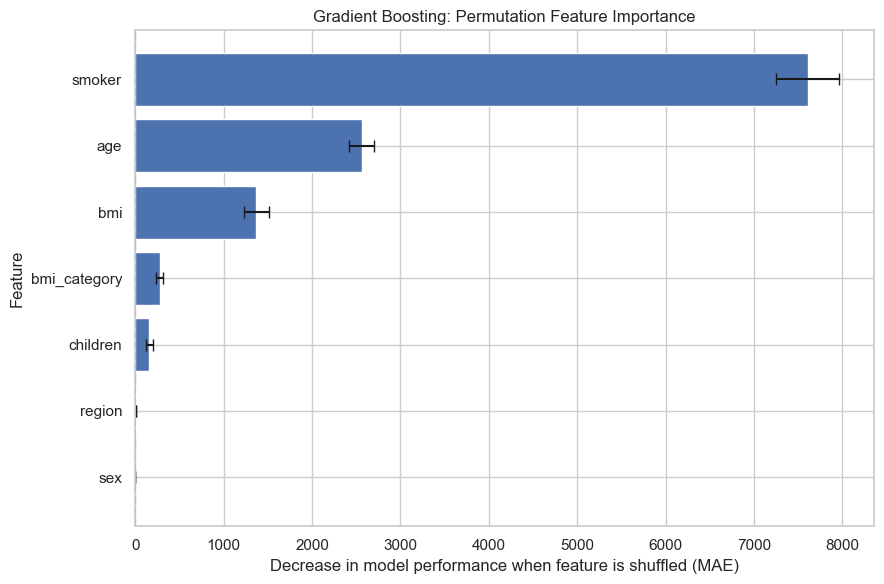

In [27]:

# ============================================================
# 10. PERMUTATION FEATURE IMPORTANCE — PLOT
# ============================================================


# Sort features from lowest to highest for a horizontal bar chart
importance_plot = importance_df.sort_values(
    "Importance", ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    importance_plot["Feature"],
    importance_plot["Importance"],
    xerr=importance_plot["Std"],
    capsize=4
)

plt.axvline(x=0, linestyle="--")
plt.xlabel("Decrease in model performance when feature is shuffled (MAE)")
plt.ylabel("Feature")
plt.title("Gradient Boosting: Permutation Feature Importance")
plt.tight_layout()
plt.show()

**Figure: Gradient Boosting Feature Importance**

The feature-importance analysis shows that smoking status is the most influential feature in predicting insurance charges, followed by age and BMI. The remaining features, including children, region and sex, have comparatively little predictive importance in this model. These results reflect the model's use of the available features and do not necessarily indicate causal relationships.

## Final Output: Predicted Insurance Charges

The complete output, including all input features, actual insurance charges and predicted charges, was exported to `output/insurance_predictions.csv`.



In [29]:
# ============================================================
# FINAL OUTPUT — SAVE PREDICTIONS TO CSV
# ============================================================


# Predict charges for the cleaned dataset
X_all = DATA_Cleaned.drop(columns="charges")
y_all = DATA_Cleaned["charges"]

# Include all original features and actual charges
prediction_output = DATA_Cleaned.copy()

# Add predicted insurance charges
prediction_output["predicted_charges"] = best_model.predict(X_all)

# Create the data folder if it does not exist
os.makedirs("data", exist_ok=True)

# Save the complete output as a CSV file
output_path = os.path.join("output", "insurance_predictions.csv")
prediction_output.to_csv(output_path, index=False)

print(f"CSV file saved to: {os.path.abspath(output_path)}")
print(f"Rows: {len(prediction_output)}")
print(f"Columns: {len(prediction_output.columns)}")

# Display the first 10 rows
display(prediction_output.head(10).round(2))

CSV file saved to: D:\Code\Assessment 2\code-institute_Assessment_2_Healthcare_Insurance_ML\code-institute-_-Assessment-2-Healthcare-Insurance-ML\output\insurance_predictions.csv
Rows: 1337
Columns: 9


,age,sex,bmi,children,smoker,region,charges,bmi_category,predicted_charges
0,19,female,27.90,0,yes,southwest,16884.92,Overweight,18142.47
1,18,male,33.77,1,no,southeast,1725.55,Obese,4902.03
2,28,male,33.00,3,no,southeast,4449.46,Obese,6690.52
3,33,male,22.70,0,no,northwest,21984.47,Normal,5531.15
4,32,male,28.88,0,no,northwest,3866.86,Overweight,4783.59
5,31,female,25.74,0,no,southeast,3756.62,Overweight,4783.59
6,46,female,33.44,1,no,southeast,8240.59,Obese,9253.25
7,37,female,27.74,3,no,northwest,7281.51,Overweight,7823.52
8,37,male,29.83,2,no,northeast,6406.41,Overweight,7930.31
9,60,female,25.84,0,no,northwest,28923.14,Overweight,14240.35


# 10. Conclusion and Recommendations

This project investigated the prediction of healthcare insurance charges using machine learning regression models. A Mean Baseline was first established as a reference point, followed by Linear Regression and more advanced models, including Ridge Regression, Random Forest, Extra Trees and Gradient Boosting. Model performance was evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and the coefficient of determination (R²).

Five-fold cross-validation identified Gradient Boosting as the strongest overall candidate among the evaluated models. It achieved a mean MAE of 2,679.82, mean RMSE of 4,592.16 and mean R² of 0.8433. On the held-out test set, the model achieved an MAE of 2,603.04, an RMSE of 4,370.82 and an R² of 0.8960, demonstrating strong predictive performance on the available data.

Feature-importance analysis identified smoking status as the most influential feature, followed by age and BMI. Permutation importance supported the importance of these features in the model's predictions. However, feature importance indicates predictive contribution rather than causation.

Visual evaluation revealed that, although many predictions were close to the actual charges, some high-cost observations were substantially underestimated. This highlights an important limitation of the model and the available dataset. Insurance charges may also depend on medical conditions, treatment requirements and other health-related factors that were not included in the available features. Their absence may limit the model's ability to predict unusually high charges accurately, although the current analysis cannot establish the causes of individual prediction errors.

Future work could investigate additional relevant health-related variables, examine observations with large residuals, and assess whether further model tuning improves predictive performance. Any improvements should be evaluated using appropriate validation procedures and an independent test set.

Overall, Gradient Boosting was the leading candidate in this analysis, providing better predictive performance than the linear models and a useful basis for understanding insurance-charge patterns. Nevertheless, its predictions should be interpreted with caution, particularly for individuals with unusually high charges. The findings demonstrate both the value of machine learning for insurance-cost prediction and the importance of data quality, feature availability and critical evaluation of model limitations.